In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환

In [3]:
# logisticRegression 이진분류 -> 다중분류
fish = pd.read_csv('data/fish_logistic.csv')

In [6]:
fish['Species'].unique() # 7개의 'Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt'
print()

In [ ]:
# 데이터 전처리
data = fish[fish.columns[1:]].values
label = fish['Species'].values

In [13]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [14]:
# logisticRegression - 정규화작업 해야 함.
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [55]:
# 다중분류
# C(대문자표기) - alpha,C 규제 : 높아지면 완화, 낮아지면 강화
# alpha for문 그래프로 가장 최적화된 규제를 찾아서 적용 
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
lr = LogisticRegression(C=20,max_iter=1000)
lr.fit(train_scaled,train_label)
print()

In [60]:
# 다중분류
# C(대문자표기) - alpha,C 규제 : 높아지면 완화, 낮아지면 강화
# alpha for문 그래프로 가장 최적화된 규제를 찾아서 적용 
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc: 
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

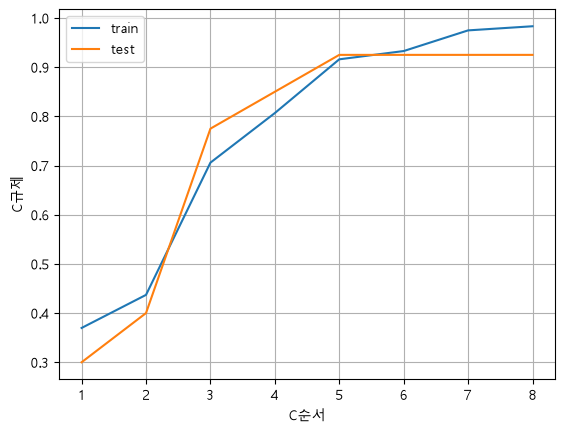

In [64]:
# C의 규제 선그래프
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [21]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [24]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
from scipy.special import softmax
soft1 = softmax(decisions,axis=1)  #axis =1:행방향 / axis=0:열방향
np.round(soft1,decimals=3)

array([[0.   , 0.014, 0.842, 0.   , 0.135, 0.007, 0.003],
       [0.   , 0.003, 0.044, 0.   , 0.007, 0.946, 0.   ],
       [0.   , 0.   , 0.034, 0.934, 0.015, 0.016, 0.   ],
       [0.011, 0.034, 0.305, 0.006, 0.567, 0.   , 0.076],
       [0.   , 0.   , 0.904, 0.002, 0.089, 0.002, 0.001]])

In [25]:
print('train 정확도 : ',lr.score(train_scaled,train_label))
print('test 정확도 : ',lr.score(test_scaled,test_label))

train 정확도 :  0.9327731092436975
test 정확도 :  0.925


In [ ]:
# 242.0	25.4	30.0	11.52	4.0200
# 290.0	26.3	31.2	12.48	4.3056
# 무게, 길이,대각선, 높이, 넓이를 입력받아
# 분류생선과 확률을 출력하시오.
# 분류 생선 : 93.1%의 확률로 Bream 판별됩니다.


In [37]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [54]:
# in_data= input('무게, 길이,대각선, 높이, 넓이를 입력하세요>> 예)242.0,25.4,30.0,11.52,4.0200')
# in_data = '242.0,25.4,30.0,11.52,4.0200'
# in_data = '55,14.7,16.5,6.8475,2.3265'
in_data = '32,13.7,14.7,3.528,1.9992' 
# in_data = '300,35,38.8,5.9364,4.3844' 
in_data = in_data.split(',')
in_data = list(map(float,in_data))

# 정규화
in_data_scaled = ss.transform([in_data])

# 예측 - 'Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'
result = lr.predict(in_data_scaled)
result2 = lr.predict_proba(in_data_scaled)
if result[0] == 'Bream':
    result3 = result2[0][0]
elif result[0] == 'Parkki':
    result3 = result2[0][1]
elif result[0] == 'Perch':
    result3 = result2[0][2]
elif result[0] == 'Pike':
    result3 = result2[0][3]
elif result[0] == 'Roach':
    result3 = result2[0][4]
elif result[0] == 'Smelt':
    result3 = result2[0][5]
elif result[0] == 'Whitefish':
    result3 = result2[0][6]
print("test : ",result3)
# 분류 생선 : 93.1%의 확률로 Bream 판별됩니다.
print(f"분류 생선 : {result3*100:.2f}%의 확률로 {result[0]}  판별됩니다.")

test :  0.5153248862437586
분류 생선 : 51.53%의 확률로 Perch  판별됩니다.
